# Predicting Annual Immigration to Canada Using Machine Learning

**Student:** Hajar Elidrissi

## Abstract

This project uses immigration data to Canada by country of citizenship from 1980 to 2013. The purpose is to explore immigration patterns and test whether machine learning can predict annual immigration counts using previous years' data. The project includes data exploration, data visualization, data preparation, model training, and model evaluation. A baseline model and a Random Forest regression model will be compared to understand their prediction performance.

## 1. Introduction

Immigration is an important part of Canada's population and social development. Studying immigration data can help identify changes over time and understand which countries and continents contribute to immigration.

In this project, machine learning techniques are used to study immigration to Canada from 1980 to 2013. Historical immigration counts and country-level information will be used to build a model that predicts annual immigration counts.

## 2. Research Question

Can previous-year immigration counts and country-level information help predict annual immigration to Canada by country of citizenship?

## Project Objectives

- Explore the immigration dataset using tables and charts.
- Identify immigration trends by year, country, and continent.
- Prepare the data for machine learning.
- Compare a baseline model with a Random Forest regression model.
- Evaluate model performance using MAE, RMSE, and R-squared.

In [258]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option("display.max_columns", 50)

## 3. Dataset Description

The dataset contains immigration counts for Canada by country of citizenship from 1980 to 2013. It includes country information such as continent, region, and development group, as well as annual immigration counts.

The original dataset is organized in a wide format, where each year has its own column. For this project, the data will be transformed into a long format, with one row for each country and year. This structure makes it easier to analyze yearly trends and create features for machine learning.

**Data source:** [Canada Immigration Data](https://docs.google.com/spreadsheets/d/1OGs8KoHGEZDxyFdaxAKmZbeO1BiSWVQ6/edit)

In [259]:
DATA_URL = "https://docs.google.com/spreadsheets/d/1OGs8KoHGEZDxyFdaxAKmZbeO1BiSWVQ6/export?format=xlsx"

raw = pd.read_excel(
    DATA_URL,
    sheet_name="Canada by Citizenship",
    header=20
)

raw.columns = [str(col).strip() for col in raw.columns]

print("Dataset shape:", raw.shape)
print("Column names:")
print(raw.columns.tolist())

display(raw.head())

Dataset shape: (197, 43)
Column names:
['Type', 'Coverage', 'OdName', 'AREA', 'AreaName', 'REG', 'RegName', 'DEV', 'DevName', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013']


,Type,Coverage,OdName,AREA,AreaName,REG,RegName,DEV,DevName,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
0,Immigrants,Foreigners,Afghanistan,935,Asia,5501,Southern Asia,902,Developing regions,16,39,39,47,71,340,496,741,828,1076,1028,1378,1170,713,858,1537,2212,2555,1999,2395,3326,4067,3697,3479,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
1,Immigrants,Foreigners,Albania,908,Europe,925,Southern Europe,901,Developed regions,1,0,0,0,0,0,1,2,2,3,3,21,56,96,71,63,113,307,574,1264,1816,1602,1021,853,1450,1223,856,702,560,716,561,539,620,603
2,Immigrants,Foreigners,Algeria,903,Africa,912,Northern Africa,902,Developing regions,80,67,71,69,63,44,69,132,242,434,491,872,795,717,595,1106,2054,1842,2292,2389,2867,3418,3406,3072,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
3,Immigrants,Foreigners,American Samoa,909,Oceania,957,Polynesia,902,Developing regions,0,1,0,0,0,0,0,1,0,1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
4,Immigrants,Foreigners,Andorra,908,Europe,925,Southern Europe,901,Developed regions,0,0,0,0,0,0,2,0,0,0,3,0,1,0,0,0,0,0,2,0,0,1,0,2,0,0,1,1,0,0,0,0,1,1


## 4. Data Understanding and Cleaning

The first step is to inspect the dataset's structure, column names, data types, and missing values. The annual immigration columns are converted to numeric values. The dataset is then reshaped from wide format to long format so that each row represents a country and a year.

These preparation steps help organize the data for visualization and machine learning.

In [260]:
# Inspect the data structure
raw.info()

display(raw.isnull().sum().sort_values(ascending=False).head(15))

# Rename the original dataset columns to clearer names
raw = raw.rename(columns={
    "OdName": "Country",
    "AreaName": "Continent",
    "RegName": "Region"
})

# Identify country information and year columns
group_columns = ["Country", "Continent", "Region", "DevName"]

missing_columns = [
    col for col in group_columns
    if col not in raw.columns
]

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

year_columns = [
    str(year) for year in range(1980, 2014)
    if str(year) in raw.columns
]

if not year_columns:
    raise ValueError("No year columns from 1980 to 2013 were found.")

# Select the required columns
wide = raw[group_columns + year_columns].copy()

wide = wide.dropna(subset=["Country"])
wide["Country"] = wide["Country"].astype(str).str.strip()

wide = wide[~wide["Country"].isin(["Total", "World"])].copy()

wide = wide[wide["Continent"] != "World"].copy()

# Convert yearly values to numeric
for col in year_columns:
    wide[col] = pd.to_numeric(wide[col], errors="coerce")

# Remove duplicate country rows
wide = wide.drop_duplicates(subset=["Country"])

# Convert the dataset from wide format to long format
df = wide.melt(
    id_vars=group_columns,
    value_vars=year_columns,
    var_name="Year",
    value_name="Immigrants"
)

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Immigrants"] = pd.to_numeric(df["Immigrants"], errors="coerce")

df = df.dropna(
    subset=["Year", "Immigrants", "Country"]
).copy()

df["Year"] = df["Year"].astype(int)
df["Immigrants"] = df["Immigrants"].clip(lower=0)

df = df.sort_values(
    ["Country", "Year"]
).reset_index(drop=True)

print("Cleaned data shape:", df.shape)
display(df.head())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 43 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Type      197 non-null    object
 1   Coverage  197 non-null    object
 2   OdName    197 non-null    object
 3   AREA      197 non-null    int64 
 4   AreaName  197 non-null    object
 5   REG       197 non-null    int64 
 6   RegName   197 non-null    object
 7   DEV       197 non-null    int64 
 8   DevName   197 non-null    object
 9   1980      197 non-null    int64 
 10  1981      197 non-null    int64 
 11  1982      197 non-null    int64 
 12  1983      197 non-null    int64 
 13  1984      197 non-null    int64 
 14  1985      197 non-null    int64 
 15  1986      197 non-null    int64 
 16  1987      197 non-null    int64 
 17  1988      197 non-null    int64 
 18  1989      197 non-null    int64 
 19  1990      197 non-null    int64 
 20  1991      197 non-null    int64 
 21  1992      197 no

,0
Type,0
Coverage,0
OdName,0
AREA,0
AreaName,0
REG,0
RegName,0
DEV,0
DevName,0
1980,0


Cleaned data shape: (6630, 6)


,Country,Continent,Region,DevName,Year,Immigrants
0,Afghanistan,Asia,Southern Asia,Developing regions,1980,16
1,Afghanistan,Asia,Southern Asia,Developing regions,1981,39
2,Afghanistan,Asia,Southern Asia,Developing regions,1982,39
3,Afghanistan,Asia,Southern Asia,Developing regions,1983,47
4,Afghanistan,Asia,Southern Asia,Developing regions,1984,71


,Year,Immigrants
count,6630.000000,6630.000000
mean,1996.500000,966.689744
std,9.811448,3216.945526
min,1980.000000,0.000000
25%,1988.000000,6.000000
50%,1996.500000,99.000000
75%,2005.000000,581.750000
max,2013.000000,42584.000000


In [261]:

print("Is 'Total' present?", (wide["Country"] == "Total").any())
print("Is 'World' present?", (wide["Country"] == "World").any())
print("Number of unique country names:", wide["Country"].nunique())


Is 'Total' present? False
Is 'World' present? False
Number of unique country names: 195


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps reveal patterns and differences in the dataset before machine learning is applied. Tables and charts are used to examine annual immigration totals, compare continents, identify the countries with the highest total immigration, and understand the distribution of immigration counts.

The visualizations also help identify whether immigration patterns change over time and whether some countries have much larger immigration counts than others.

In [262]:
# Table 1: Annual immigration totals
yearly_totals = (
    df.groupby("Year", as_index=False)["Immigrants"]
      .sum()
)

display(yearly_totals)

# Table 2: Total immigration by continent
continent_totals = (
    df.groupby("Continent", as_index=False)["Immigrants"]
      .sum()
      .sort_values("Immigrants", ascending=False)
)

display(continent_totals)

# Table 3: Top 10 countries by total immigration
top_countries = (
    df.groupby("Country")["Immigrants"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

display(top_countries)

,Year,Immigrants
0,1980,99137
1,1981,110563
2,1982,104271
3,1983,75550
4,1984,73417
5,1985,69978
6,1986,86048
7,1987,134771
8,1988,139306
9,1989,164432


,Continent,Immigrants
1,Asia,3317794
2,Europe,1410947
3,Latin America and the Caribbean,765148
0,Africa,618948
4,Northern America,241142
5,Oceania,55174


,Country,Immigrants
0,India,691904
1,China,659962
2,United Kingdom of Great Britain and Northern I...,551500
3,Philippines,511391
4,Pakistan,241600
5,United States of America,241122
6,Iran (Islamic Republic of),175923
7,Sri Lanka,148358
8,Republic of Korea,142581
9,Poland,139241


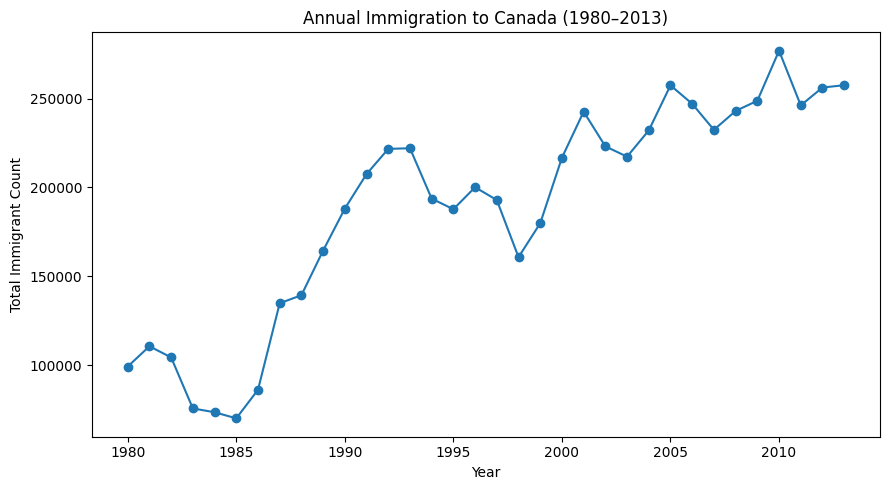

In [263]:
plt.figure(figsize=(9, 5))
plt.plot(yearly_totals["Year"], yearly_totals["Immigrants"], marker="o")
plt.title("Annual Immigration to Canada (1980–2013)")
plt.xlabel("Year")
plt.ylabel("Total Immigrant Count")
plt.tight_layout()
plt.show()

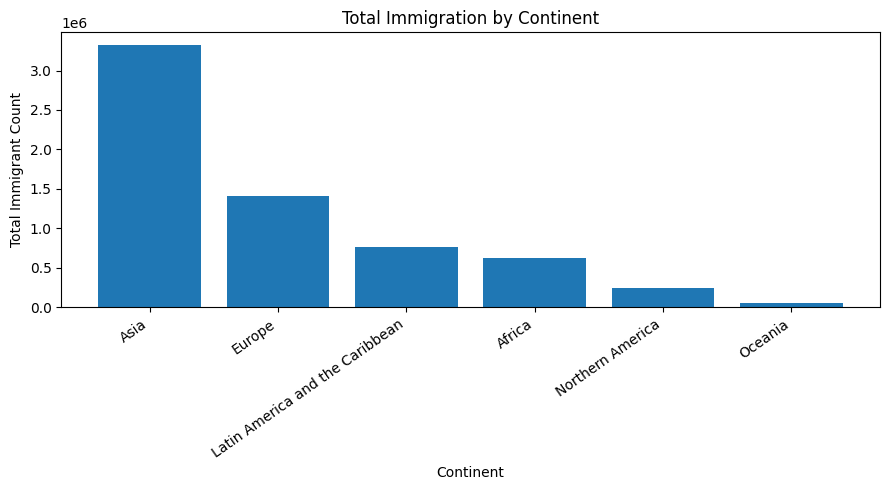

In [264]:
plt.figure(figsize=(9, 5))
plt.bar(continent_totals["Continent"], continent_totals["Immigrants"])
plt.title("Total Immigration by Continent")
plt.xlabel("Continent")
plt.ylabel("Total Immigrant Count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

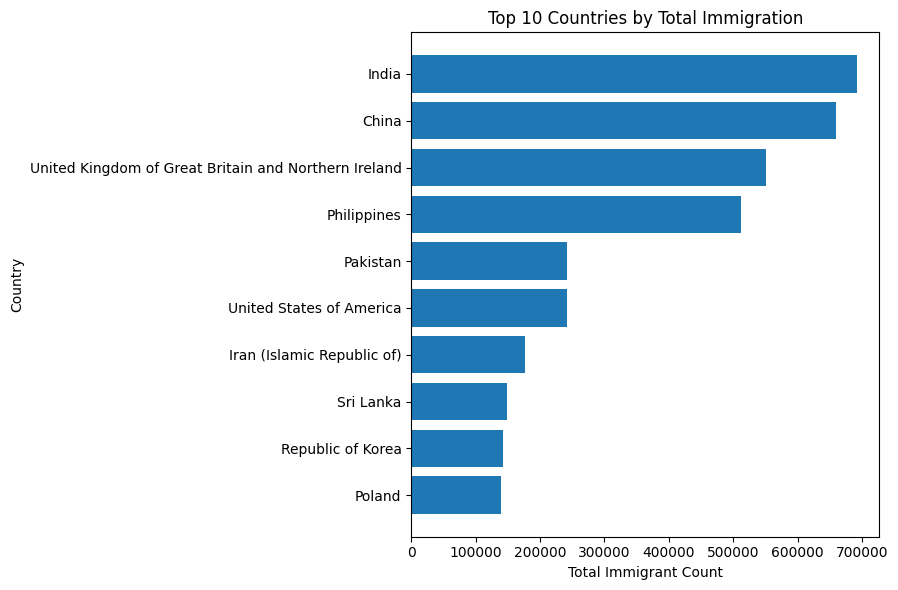

In [265]:
top10 = (
    df.groupby("Country")["Immigrants"]
      .sum()
      .nlargest(10)
      .sort_values()
)

plt.figure(figsize=(9, 6))
plt.barh(top10.index, top10.values)
plt.title("Top 10 Countries by Total Immigration")
plt.xlabel("Total Immigrant Count")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

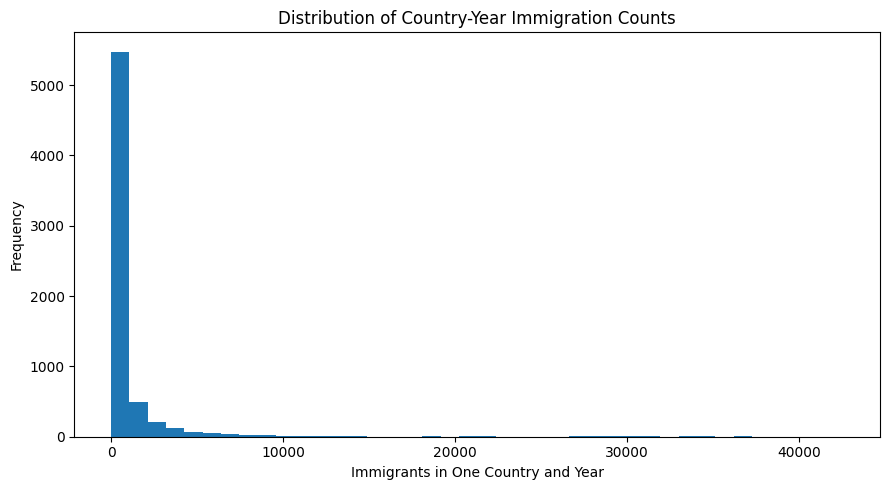

In [266]:
plt.figure(figsize=(9, 5))
plt.hist(df["Immigrants"], bins=40)
plt.title("Distribution of Country-Year Immigration Counts")
plt.xlabel("Immigrants in One Country and Year")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

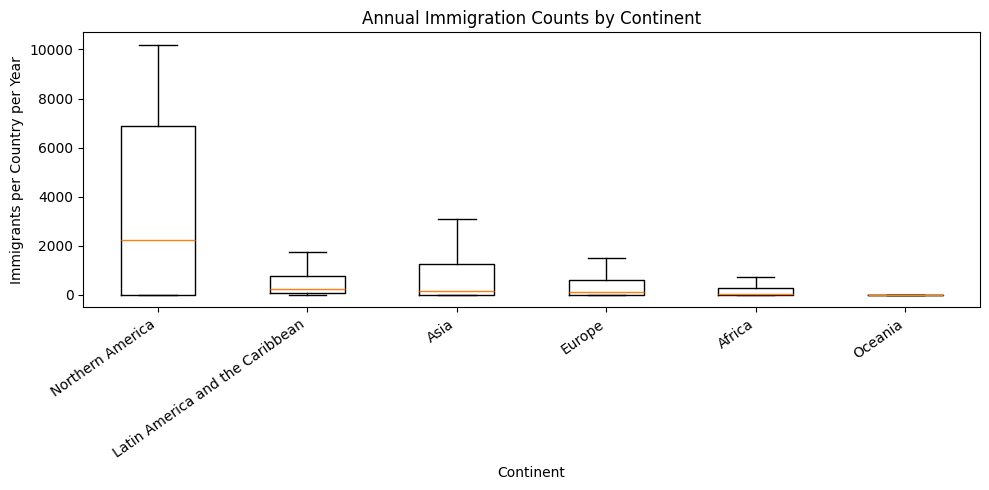

In [267]:
continent_order = (
    df.groupby("Continent")["Immigrants"]
      .median()
      .sort_values(ascending=False)
      .index.tolist()
)

box_data = [
    df.loc[df["Continent"] == continent, "Immigrants"].values
    for continent in continent_order
]

plt.figure(figsize=(10, 5))
plt.boxplot(box_data, tick_labels=continent_order, showfliers=False)
plt.title("Annual Immigration Counts by Continent")
plt.xlabel("Continent")
plt.ylabel("Immigrants per Country per Year")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

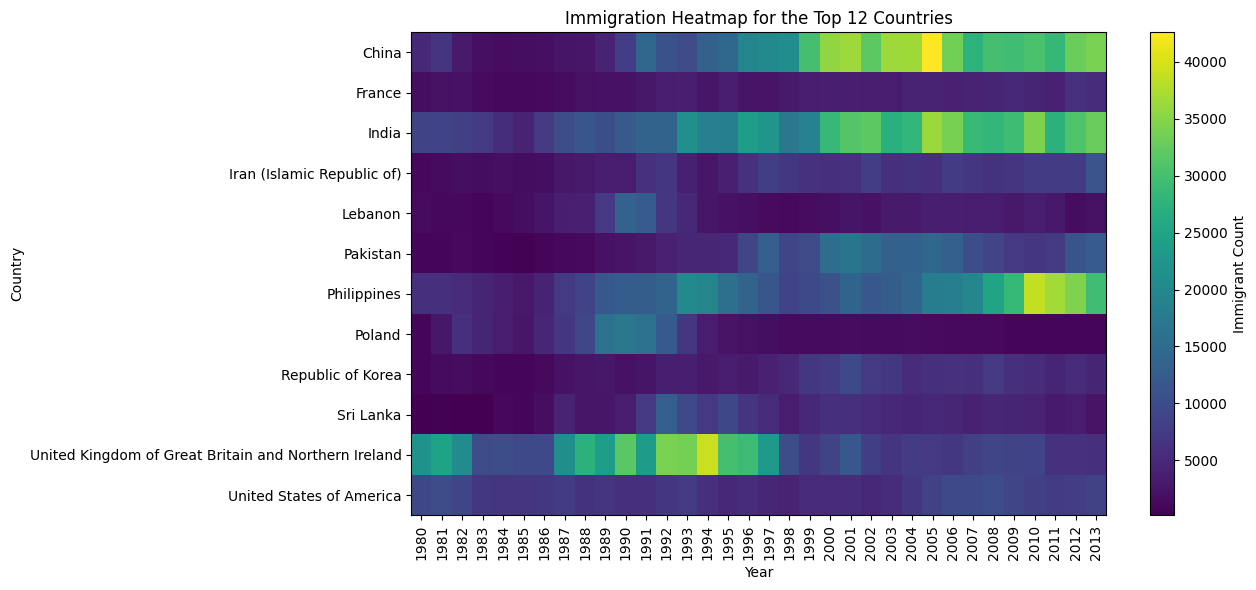

In [268]:
top12 = (
    df.groupby("Country")["Immigrants"]
      .sum()
      .nlargest(12)
      .index
)

heatmap_data = (
    df[df["Country"].isin(top12)]
      .pivot_table(
          index="Country",
          columns="Year",
          values="Immigrants",
          aggfunc="sum"
      )
      .fillna(0)
)

plt.figure(figsize=(13, 6))
plt.imshow(heatmap_data.values, aspect="auto", interpolation="nearest")
plt.title("Immigration Heatmap for the Top 12 Countries")
plt.xlabel("Year")
plt.ylabel("Country")
plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns.astype(str),
    rotation=90
)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.colorbar(label="Immigrant Count")
plt.tight_layout()
plt.show()

## 6. Data Preparation

Machine learning requires features that help predict the target variable. In this project, the target is the annual immigration count for each country. Features include the year, country information, immigration counts from the previous three years, and the average immigration count from those previous years.

To simulate prediction of future immigration, the model is trained on data through 2010 and tested on data from 2011 to 2013. This time-based split is more appropriate than randomly mixing years between training and testing.

In [269]:
# Create historical features for each country
grouped = df.groupby("Country", sort=False)["Immigrants"]

df["Lag_1"] = grouped.shift(1)
df["Lag_2"] = grouped.shift(2)
df["Lag_3"] = grouped.shift(3)

df["Previous_3_Year_Average"] = (
    df.groupby("Country", sort=False)["Immigrants"]
      .transform(
          lambda s: s.shift(1).rolling(3, min_periods=3).mean()
      )
)

model_df = df.dropna(
    subset=["Lag_1", "Lag_2", "Lag_3", "Previous_3_Year_Average"]
).copy()

features = [
    "Country", "Continent", "Region", "DevName", "Year",
    "Lag_1", "Lag_2", "Lag_3", "Previous_3_Year_Average"
]

target = "Immigrants"

train_df = model_df[model_df["Year"] <= 2010].copy()
test_df = model_df[model_df["Year"].between(2011, 2013)].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training years:", train_df["Year"].min(), "-", train_df["Year"].max())
print("Testing years:", test_df["Year"].min(), "-", test_df["Year"].max())

display(X_train.head())

Training rows: 5460
Testing rows: 585
Training years: 1983 - 2010
Testing years: 2011 - 2013


,Country,Continent,Region,DevName,Year,Lag_1,Lag_2,Lag_3,Previous_3_Year_Average
3,Afghanistan,Asia,Southern Asia,Developing regions,1983,39.0,39.0,16.0,31.333333
4,Afghanistan,Asia,Southern Asia,Developing regions,1984,47.0,39.0,39.0,41.666667
5,Afghanistan,Asia,Southern Asia,Developing regions,1985,71.0,47.0,39.0,52.333333
6,Afghanistan,Asia,Southern Asia,Developing regions,1986,340.0,71.0,47.0,152.666667
7,Afghanistan,Asia,Southern Asia,Developing regions,1987,496.0,340.0,71.0,302.333333


## 7. Model Building

Two regression models are used in this project.

The first model is a Dummy Regressor. It provides a simple baseline by predicting the average immigration count from the training data.

The second model is a Random Forest Regressor. It combines multiple decision trees and can learn more complex relationships between historical immigration counts and country-level information.

Categorical features are converted using one-hot encoding. Both models use the same training and testing datasets so their performance can be compared fairly.

In [270]:
categorical_features = ["Country", "Continent", "Region", "DevName"]

numeric_features = [
    "Year", "Lag_1", "Lag_2", "Lag_3", "Previous_3_Year_Average"
]

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", encoder, categorical_features),
        ("numeric", SimpleImputer(strategy="median"), numeric_features)
    ]
)

# Baseline model
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

# Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)

print("Both models have been trained.")

Both models have been trained.


## 8. Model Evaluation

The models are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

MAE measures the average absolute difference between actual and predicted values. RMSE gives more weight to larger errors. R² measures how well the predictions explain variation in the target values compared with a simple reference prediction.

Lower MAE and RMSE values indicate smaller prediction errors. A higher R² generally indicates better performance, although R² can be negative when a model performs poorly on the test data.

In [271]:
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    evaluate_model("Dummy Baseline", y_test, baseline_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
])

display(results.round(3))

,Model,MAE,RMSE,R2
0,Dummy Baseline,1517.101,4174.867,-0.006
1,Random Forest,207.922,545.339,0.983


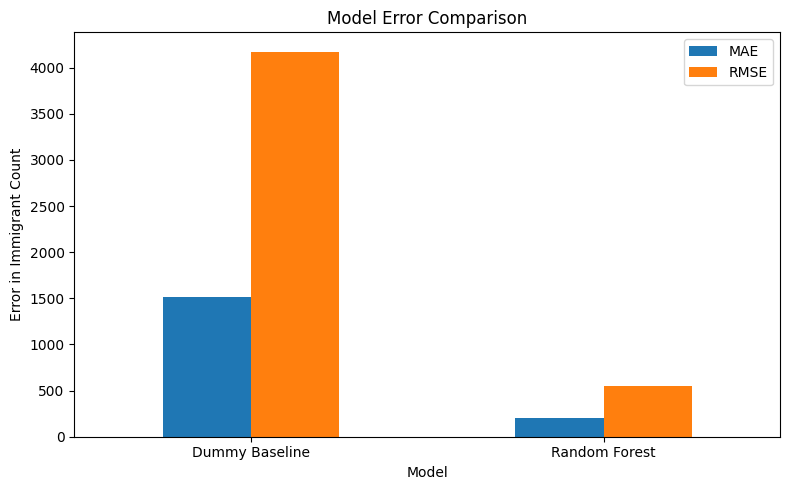

In [272]:
results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Error Comparison")
plt.ylabel("Error in Immigrant Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

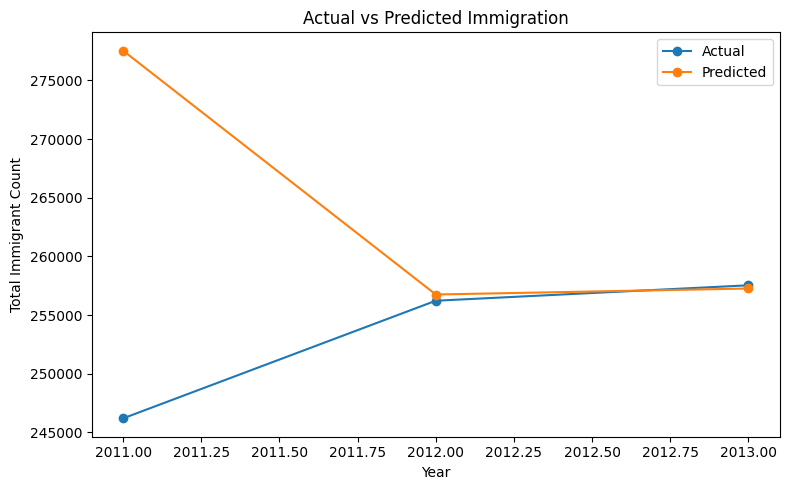

,Country,Year,Immigrants,Random_Forest_Prediction
31,Afghanistan,2011,2203,2028.473304
32,Afghanistan,2012,2635,2704.200109
33,Afghanistan,2013,2004,2750.085280
65,Albania,2011,539,653.197837
66,Albania,2012,620,573.536278
67,Albania,2013,603,666.180292
99,Algeria,2011,4325,4743.555429
100,Algeria,2012,3774,4802.620649
101,Algeria,2013,4331,3884.792252
133,American Samoa,2011,0,0.294482


In [273]:
comparison = test_df[["Country", "Year", "Immigrants"]].copy()
comparison["Random_Forest_Prediction"] = rf_predictions

annual_actual = comparison.groupby("Year")["Immigrants"].sum()
annual_predicted = comparison.groupby("Year")["Random_Forest_Prediction"].sum()

plt.figure(figsize=(8, 5))
plt.plot(annual_actual.index, annual_actual.values, marker="o", label="Actual")
plt.plot(annual_predicted.index, annual_predicted.values, marker="o", label="Predicted")

plt.title("Actual vs Predicted Immigration")
plt.xlabel("Year")
plt.ylabel("Total Immigrant Count")
plt.legend()
plt.tight_layout()
plt.show()

display(comparison.head(15))

## 9. Conclusion

This project analyzed immigration to Canada from 1980 to 2013 using exploratory data analysis and machine learning. Tables and visualizations helped identify immigration trends, compare continents, and examine the main countries of origin.

The Random Forest Regressor performed better than the Dummy Regressor on the test data. The Random Forest model achieved a Mean Absolute Error (MAE) of 207.922, a Root Mean Squared Error (RMSE) of 545.339, and an R-squared value of 0.983. In comparison, the Dummy Baseline had an MAE of 1517.101, an RMSE of 4174.867, and an R-squared value of -0.006. These results show that the Random Forest model made substantially more accurate predictions on the test data.

However, the results depend on the quality of the dataset and the selected features. The model's predictions should not be considered a guarantee of future immigration patterns.


## 10. References

United Nations. (n.d.). *Canada by citizenship: Immigration data, 1980–2013* [Data set]. Google Sheets. https://docs.google.com/spreadsheets/d/1OGs8KoHGEZDxyFdaxAKmZbeO1BiSWVQ6/edit

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Scikit-learn developers. (n.d.). *RandomForestRegressor*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

Scikit-learn developers. (n.d.). *Model evaluation: Quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html